In [1]:
import os, glob, h5py
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
class_names = ["meningioma", "glioma", "pituitary"]

saved = torch.load(glob.glob("/kaggle/input/**/slices_224.pt", recursive=True)[0])
X, y = saved["X"].float(), saved["y"]
csv_path = glob.glob("/kaggle/input/**/*slice_info*.csv", recursive=True)[0]
df = pd.read_csv(csv_path, dtype={"slice_id": str, "pid": str})
if "slice_ids" in saved:
    df = df.set_index("slice_id").loc[saved["slice_ids"]].reset_index()
assert len(df) == len(X) == len(y)
assert (df["label"].to_numpy() - 1 == y.numpy()).all(), "rows of X and the CSV don't line up"
df["id_format"] = np.where(df["pid"].str.startswith("MR"), "MR-prefixed", "numeric")
idx = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}

mat_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob("/kaggle/input/**/*.mat", recursive=True)}
df["path"] = df["slice_id"].map(mat_paths)
assert df["path"].notna().all(), "attach the original brain tumor dataset too"

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def prep(i):
    return ((X[i].repeat(3, 1, 1) - MEAN) / STD)[None]

model = models.resnet18()
model.fc = nn.Linear(model.fc.in_features, 3)
model.load_state_dict(torch.load(glob.glob("/kaggle/input/**/resnet18_best.pth", recursive=True)[0],
                                 map_location="cpu"))
model = model.to(device).eval()
print("ready:", X.shape)

ready: torch.Size([3064, 1, 224, 224])


In [2]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, i, target=None):
        x = prep(i).to(device)
        self.model.zero_grad()
        logits = self.model(x)
        probs = F.softmax(logits, dim=1)[0].detach().cpu().numpy()
        pred = int(logits.argmax(1))
        t = pred if target is None else target
        logits[0, t].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts.detach()).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), pred, probs

model.layer4._forward_hooks.clear()    # remove hooks left from earlier runs

cam_tool = GradCAM(model, model.layer4)

ev = np.concatenate([idx["val"], idx["test"]])
preds = []
with torch.no_grad():
    for k in range(0, len(ev), 64):
        xb = ((X[ev[k:k+64]].repeat(1, 3, 1, 1) - MEAN) / STD).to(device)
        preds += model(xb).argmax(1).cpu().tolist()
ev_df = df.iloc[ev].copy()
ev_df["pred"], ev_df["true"] = preds, y[ev].numpy()
ev_df["correct"] = ev_df.pred == ev_df.true
ev_df["group"] = np.where(ev_df.label == 2, "glioma, " + ev_df.id_format, ev_df.class_name)
print(ev_df.groupby("group")["correct"].agg(["size", "mean"]).round(3))

                     size   mean
group                           
glioma, MR-prefixed   249  0.984
glioma, numeric        36  0.611
meningioma            123  0.886
pituitary             207  0.995


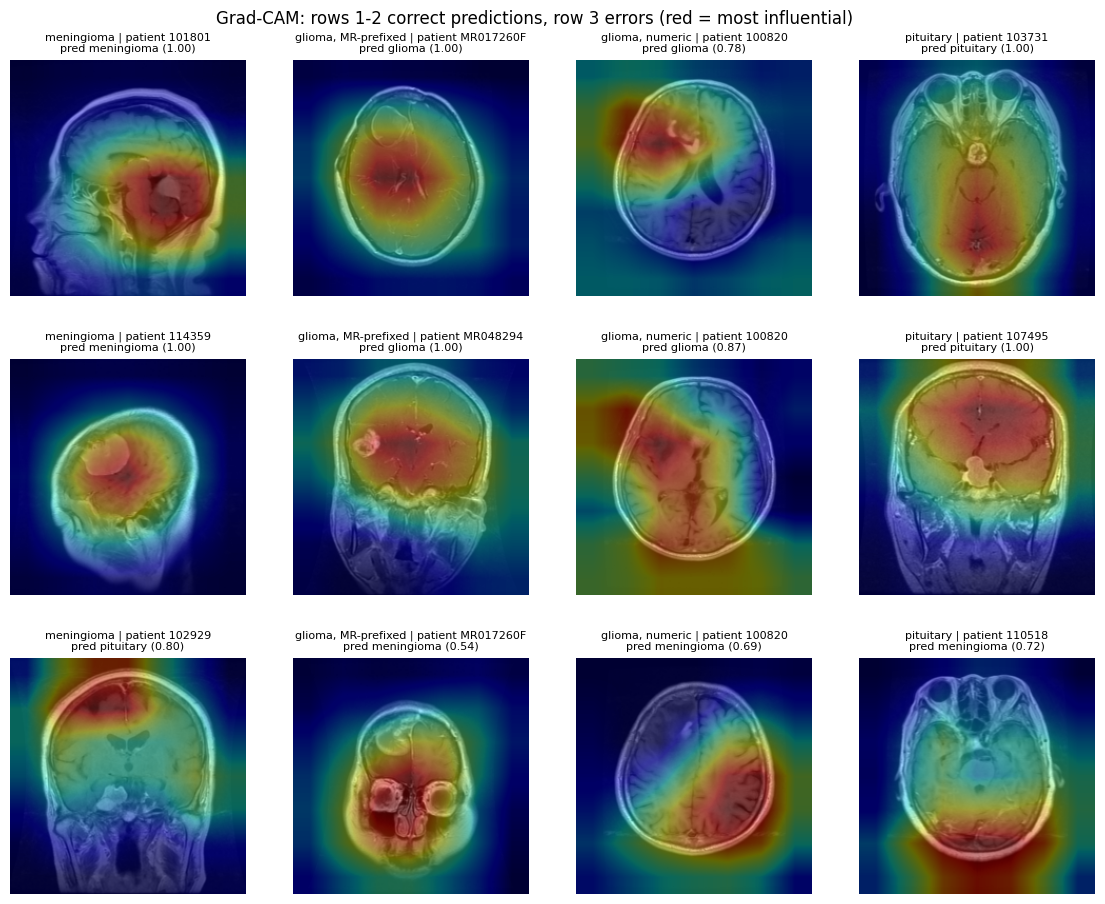

In [3]:
def show(ax, i):
    cam, pred, probs = cam_tool(i)
    ax.imshow(X[i, 0], cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f"{ev_df.loc[i, 'group']} | patient {df['pid'].iloc[i]}\n"
                 f"pred {class_names[pred]} ({probs[pred]:.2f})", fontsize=8)
    ax.axis("off")

rng = np.random.default_rng(0)
groups = ["meningioma", "glioma, MR-prefixed", "glioma, numeric", "pituitary"]
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for col, g in enumerate(groups):
    ok  = ev_df[(ev_df.group == g) & ev_df.correct]
    bad = ev_df[(ev_df.group == g) & ~ev_df.correct]
    for row in range(2):
        show(axes[row, col], rng.choice(ok.index))
    if len(bad):
        show(axes[2, col], rng.choice(bad.index))
    else:
        axes[2, col].axis("off")
fig.suptitle("Grad-CAM: rows 1-2 correct predictions, row 3 errors (red = most influential)", y=0.92)
plt.savefig("/kaggle/working/gradcam_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
def load_mask(path):
    with h5py.File(path, "r") as f:
        m = np.array(f["cjdata"]["tumorMask"]).T.astype(np.float32)
    m = torch.from_numpy(m)[None, None]
    return F.interpolate(m, size=(224, 224), mode="nearest")[0, 0].numpy() > 0.5

rows = []
for i in ev_df[ev_df.correct].index:
    cam, _, _ = cam_tool(i)
    m = load_mask(df["path"].iloc[i])
    if m.sum() == 0:
        continue
    share, area = cam[m].sum() / (cam.sum() + 1e-8), m.mean()
    peak = np.unravel_index(cam.argmax(), cam.shape)
    rows.append({"group": ev_df.loc[i, "group"], "pid": df["pid"].iloc[i],
                 "share_in_tumor": share, "tumor_area": area,
                 "ratio": share / area, "peak_in_tumor": bool(m[peak])})
chk = pd.DataFrame(rows)
summary = chk.groupby("group").agg(
    slices=("ratio", "size"), patients=("pid", "nunique"),
    median_share=("share_in_tumor", "median"), median_area=("tumor_area", "median"),
    median_ratio=("ratio", "median"), peak_hit_rate=("peak_in_tumor", "mean")).round(3)
print(summary)

                     slices  patients  median_share  median_area  \
group                                                              
glioma, MR-prefixed     245        14         0.045        0.020   
glioma, numeric          22         4         0.091        0.033   
meningioma              109        15         0.040        0.012   
pituitary               206        12         0.011        0.007   

                     median_ratio  peak_hit_rate  
group                                             
glioma, MR-prefixed         2.339          0.273  
glioma, numeric             2.952          0.455  
meningioma                  2.976          0.257  
pituitary                   1.553          0.010  


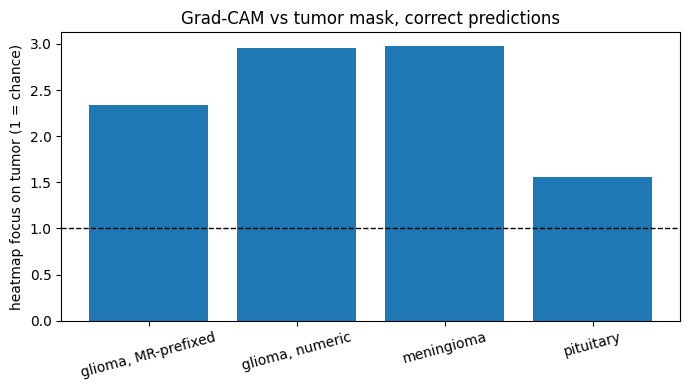

In [5]:
summary.to_csv("/kaggle/working/gradcam_mask_check_summary.csv")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index, summary.median_ratio)
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_ylabel("heatmap focus on tumor (1 = chance)")
ax.set_title("Grad-CAM vs tumor mask, correct predictions")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("/kaggle/working/gradcam_mask_check.png", dpi=150)
plt.show()